In [15]:
import os
import sys

import cartopy.crs as ccrs
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pyproj
import rasterio
import xarray as xr
from pymesh2d.geom_util.getiso import getiso_polygone
from pymesh2d.geom_util.poly_util import (
    buffer_area,
    polygon_to_node_edge,
    resample_polygon,
)
from pymesh2d.geom_util.proj_util import (
    get_local_utm_crs,
    reproject_geometry,
    reproject_node,
)
from pymesh2d.geomesh_util.border_util import clean_polygon
from pymesh2d.refine import refine
from pymesh2d.smooth import smooth
from shapely.geometry import LineString, Point

In [16]:
# Load GEBCO 2025 data from remote server

crs = pyproj.CRS.from_epsg(4326)


GEBCO = xr.open_dataset(
    "https://dap.ceda.ac.uk/thredds/dodsC/bodc/gebco/global/gebco_2025/ice_surface_elevation/netcdf/GEBCO_2025.nc"
)

# Extract the region of interest
GEBCO_sel = GEBCO.sel(
    lon=slice(-5.3117, -2.5494),
    lat=slice(43.1426, 44.03125),
)

GEBCO_sel

lon = GEBCO_sel["lon"]
lat = GEBCO_sel["lat"]
zdat = GEBCO_sel["elevation"]


utm_crs = get_local_utm_crs(crs, lon, lat)

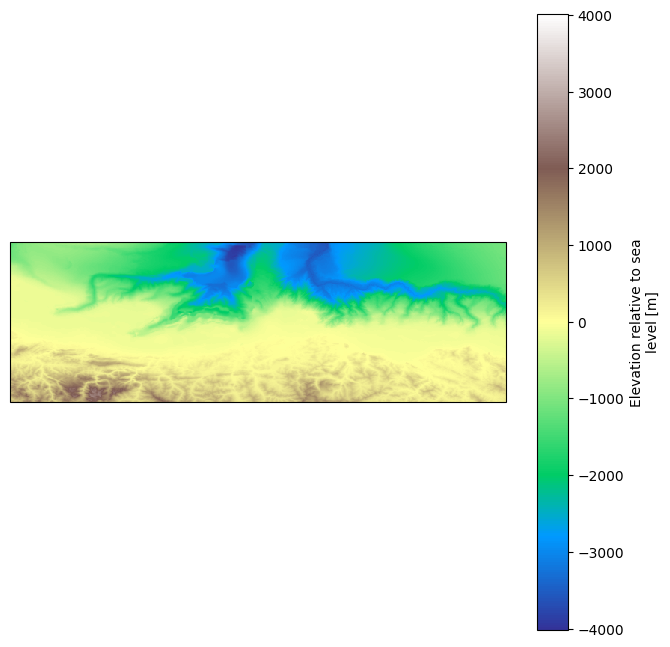

In [17]:
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"projection": ccrs.PlateCarree()})

GEBCO_sel.elevation.plot(ax=ax, transform=ccrs.PlateCarree(), cmap="terrain")

In [18]:
from shapely import make_valid
from shapely.geometry import MultiPolygon

# Extract coastline (ocean area)
polygone_cost = getiso_polygone(lon, lat, zdat, zmax=0.0)

polygone_indef = getiso_polygone(lon, lat, -zdat, zmax=5000)

cost_mp = make_valid(MultiPolygon(polygone_cost)).buffer(0)
indef_mp = make_valid(MultiPolygon(polygone_indef)).buffer(0)

Poly_dominio_prev = make_valid(cost_mp.intersection(indef_mp)).buffer(0)
Poly_dominio = max(Poly_dominio_prev.geoms, key=lambda p: p.area)

# Poly_dominio = make_valid(Poly_dominio_prev_max.intersection(Tyndall_point)).buffer(0)
# Poly_dominio = max(Poly_dominio.geoms, key=lambda p: p.area)

<GeoAxes: xlabel='longitude [degrees_east]', ylabel='latitude [degrees_north]'>

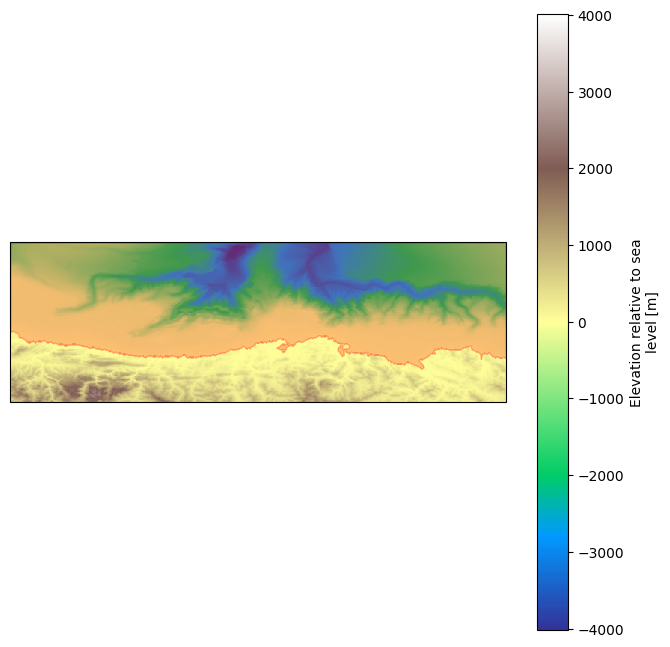

In [19]:
from shapely.geometry import MultiPolygon

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"projection": ccrs.PlateCarree()})

GEBCO_sel.elevation.plot(ax=ax, transform=ccrs.PlateCarree(), cmap="terrain")

gpd.GeoSeries(Poly_dominio).plot(
    ax=ax, color="red", alpha=0.25, edgecolor="red", transform=ccrs.PlateCarree()
)

<Axes: >

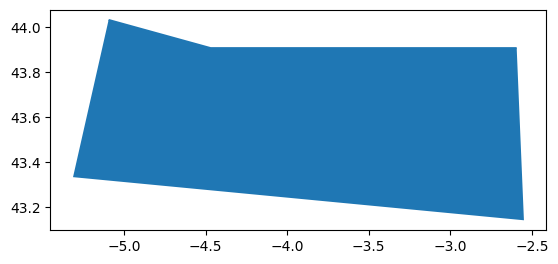

In [20]:
# Load other polygon to get out boundary 
# from Cantabria/outputs/goals_line_buffer.geojson

new_poly = gpd.read_file("outputs/goals_line_buffer.geojson")
new_poly.plot()

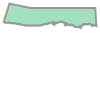

In [26]:
Poly_dominio

In [ ]:
Poly_dominio = new_poly.intersection(Poly_dominio)[1]
Poly_dominio

AttributeError: 'Polygon' object has no attribute 'plot'

In [27]:
from pymesh2d.geomesh_util.depth_field import depth_field_from_xr

depth_field = depth_field_from_xr(GEBCO_sel, crs, utm_crs)


def hfun_depth_quadratic(test, depth_field, hmin=np.inf, hmax=np.inf):
    test = np.asarray(test, dtype=float)
    if test.ndim == 1:
        test = test.reshape(1, -1)

    h = depth_field(test) if callable(depth_field) else np.asarray(depth_field)
    if np.size(h) == 1:
        h_scalar = float(np.asarray(h).reshape(-1)[0])
        h = np.full(test.shape[0], h_scalar)
    else:
        h = np.asarray(h).reshape(-1)
        if h.shape[0] != test.shape[0]:
            raise ValueError("depth_field size must match test points")

    hfun_values = 0.14 * h**2 + 28 * h + 655
    return np.clip(hfun_values, hmin, hmax)


def hfun(test):
    return hfun_depth_quadratic(test, depth_field, hmin=100, hmax=5000)

In [28]:
from scipy import ndimage


def extent_lonlat_bbox(lon_1d, lat_1d, crs_from, crs_to):
    """Boîte (xmin, xmax, ymin, ymax) des coins lon/lat projetés dans crs_to."""
    lon_1d, lat_1d = np.asarray(lon_1d), np.asarray(lat_1d)
    lon_grid, lat_grid = np.meshgrid(lon_1d, lat_1d)
    tr = pyproj.Transformer.from_crs(crs_from, crs_to, always_xy=True)
    x, y = tr.transform(lon_grid, lat_grid)
    return (
        float(np.nanmin(x)),
        float(np.nanmax(x)),
        float(np.nanmin(y)),
        float(np.nanmax(y)),
    )


def _shift_neighbor(arr, di, dj, fill=np.inf):
    out = np.full_like(arr, fill, dtype=float)
    ni, nj = arr.shape
    si0, si1 = max(0, di), ni + min(0, di)
    di0, di1 = max(0, -di), ni - max(0, di)
    sj0, sj1 = max(0, dj), nj + min(0, dj)
    dj0, dj1 = max(0, -dj), nj - max(0, dj)
    if si0 < si1 and sj0 < sj1:
        out[di0:di1, dj0:dj1] = arr[si0:si1, sj0:sj1]
    return out


def _fill_nan_nearest(arr):
    arr = np.asarray(arr, dtype=float)
    out = arr.copy()
    bad = ~np.isfinite(out)
    if not np.any(bad):
        return out
    if not np.any(np.isfinite(out)):
        raise ValueError("Aucune valeur finie pour combler les NaN")
    _, idx = ndimage.distance_transform_edt(bad, return_indices=True)
    out[bad] = out[tuple(idx[:, bad])]
    return out


def _clip_grad(h, xpts, ypts, grad_max=0.10, n_iter=None, tol=1e-6):
    h = np.asarray(h, dtype=float).copy()
    if not np.any(np.isfinite(h)):
        raise ValueError("Grille h sans valeurs finies")
    h[~np.isfinite(h)] = np.inf
    h0 = h.copy()
    dx = float(np.mean(np.diff(xpts)))
    dy = float(np.mean(np.diff(ypts)))
    neigh = [(-1, -1), (-1, 0), (-1, 1), (0, -1), (0, 1), (1, -1), (1, 0), (1, 1)]
    if n_iter is None:
        n_iter = int(2 * max(h.shape))
    for _ in range(n_iter):
        prev = h.copy()
        for di, dj in neigh:
            d = np.hypot(di * dy, dj * dx)
            if d == 0:
                continue
            h = np.minimum(h, _shift_neighbor(h, di, dj) + float(grad_max) * d)
        h = np.minimum(h, h0)
        if np.max(np.abs(h - prev)) < tol:
            break
    return h


def _grid_size(x0, x1, y0, y1, grid_res, grad, nmin, nmax):
    if grid_res != "auto":
        return int(grid_res)
    span = max(float(x1 - x0), float(y1 - y0))
    step = np.clip(800.0 * float(grad), 300.0, 2500.0)
    n = int(np.ceil(span / step)) + 1
    return int(np.clip(n, int(nmin), int(nmax)))


def precalc_hfuns(
    hfun,
    *,
    work_crs,
    extent_xy=None,
    lon=None,
    lat=None,
    geo_crs=None,
    crs_geographic=None,
    name="default",
    cache_id=None,
    max_gradient=0.20,
    gradient_mesh=None,
    min_cells=120,
    max_cells=600,
):
    """Callback maillage : taille h sur une grille lissée (|∇h| borné) en ``work_crs``.

    * ``hfun(xy)`` — ``xy`` (N, 2), colonnes x, y en **mètres** (``work_crs``).
    * **Domaine** : ``extent_xy=(xmin, xmax, ymin, ymax)`` **ou** ``lon``, ``lat`` 1D + ``geo_crs``.

    Retour : fonction ``hfuns`` avec ``.precompute()`` et ``.build()`` pour forcer la grille.

    Dépendances : numpy, scipy.ndimage, pyproj (si lon/lat). Matplotlib seulement pour ``plot_hfun``.
    """
    if cache_id is not None:
        name = str(cache_id)
    if geo_crs is None and crs_geographic is not None:
        geo_crs = crs_geographic
    g = float(gradient_mesh) if gradient_mesh is not None else float(max_gradient)

    if extent_xy is not None:
        x0, x1 = float(extent_xy[0]), float(extent_xy[1])
        y0, y1 = float(extent_xy[2]), float(extent_xy[3])
    elif lon is not None and lat is not None and geo_crs is not None:
        x0, x1, y0, y1 = extent_lonlat_bbox(lon, lat, geo_crs, work_crs)
    else:
        raise ValueError(
            "precalc_hfuns : indique extent_xy=(xmin,xmax,ymin,ymax) "
            "ou lon, lat, geo_crs (avec work_crs)."
        )

    ext_key = (round(x0, 3), round(x1, 3), round(y0, 3), round(y1, 3))
    caches = {}
    state = {"cache": None, "params": None}

    def build(grid_res="auto", max_gradient=None):
        mg = float(g if max_gradient is None else max_gradient)
        n = _grid_size(x0, x1, y0, y1, grid_res, mg, min_cells, max_cells)
        key = (name, ext_key, n, mg)
        if key in caches:
            return caches[key]
        xs = np.linspace(x0, x1, n)
        ys = np.linspace(y0, y1, n)
        xq, yq = np.meshgrid(xs, ys)
        pts = np.column_stack([xq.ravel(), yq.ravel()])
        raw = np.asarray(hfun(pts), dtype=float).reshape(n, n)
        raw = _fill_nan_nearest(raw)
        lim = _clip_grad(raw, xs, ys, grad_max=mg)
        dx = float(xs[1] - xs[0]) if n > 1 else 1.0
        dy_sp = float(ys[1] - ys[0]) if n > 1 else 1.0
        entry = {
            "h_grid": lim,
            "x_min": x0,
            "x_max": x1,
            "y_min": y0,
            "y_max": y1,
            "dx": dx,
            "dy": dy_sp,
            "grid_res": n,
            "work_crs": work_crs,
            "extent_xy": (x0, x1, y0, y1),
        }
        caches[key] = entry
        return entry

    def precompute(grid_res="auto", max_gradient=None):
        mg = float(g if max_gradient is None else max_gradient)
        cached = build(grid_res=grid_res, max_gradient=mg)
        state["cache"] = cached
        state["params"] = (grid_res, mg)
        return cached

    def lookup(xy, return_grid_res=False, max_gradient=None, grid_res="auto"):
        mg = float(g if max_gradient is None else max_gradient)
        par = (grid_res, mg)
        if state["cache"] is None or state["params"] != par:
            precompute(grid_res=grid_res, max_gradient=mg)
        c = state["cache"]
        hg = c["h_grid"]
        x_a, y_a = c["x_min"], c["y_min"]
        dx_, dy_ = c["dx"], c["dy"]
        xy = np.asarray(xy, dtype=float)
        one = xy.ndim == 1
        if one:
            xy = xy.reshape(1, -1)
        ix = np.rint((xy[:, 0] - x_a) / dx_).astype(np.int64)
        iy = np.rint((xy[:, 1] - y_a) / dy_).astype(np.int64)
        ix = np.clip(ix, 0, hg.shape[1] - 1)
        iy = np.clip(iy, 0, hg.shape[0] - 1)
        r = hg[iy, ix]
        out = float(r[0]) if one else r
        if return_grid_res:
            return out, c["grid_res"]
        return out

    lookup.precompute = precompute
    lookup.build = build
    lookup.extent_xy = (x0, x1, y0, y1)
    lookup.work_crs = work_crs
    lookup.name = name
    return lookup


def plot_hfun(
    hfuns_cb, hfun, *, figsize=(16, 5), show=True, grid_res="auto", max_gradient=None
):
    """Compare ``hfun`` (brut) et la grille lissée (``hfuns``), en coordonnées ``work_crs``."""
    if not callable(getattr(hfuns_cb, "precompute", None)):
        raise TypeError(
            "Le 1er argument doit être la fonction renvoyée par precalc_hfuns(...)."
        )
    cache = hfuns_cb.precompute(grid_res=grid_res, max_gradient=max_gradient)
    hs = cache["h_grid"]
    ny, nx = hs.shape
    xs = np.linspace(cache["x_min"], cache["x_max"], nx)
    ys = np.linspace(cache["y_min"], cache["y_max"], ny)
    xx, yy = np.meshgrid(xs, ys)
    pts = np.column_stack([xx.ravel(), yy.ravel()])
    h0 = np.asarray(hfun(pts), dtype=float).reshape(ny, nx)
    reduc = np.maximum(h0 - hs, 0.0)
    extent = [cache["x_min"], cache["x_max"], cache["y_min"], cache["y_max"]]
    import matplotlib.pyplot as plt

    fig, axes = plt.subplots(1, 3, figsize=figsize)
    for ax, data, title, cmap, lab in (
        (axes[0], h0, "hfun brut", "viridis", "h (m)"),
        (axes[1], hs, "hfuns (grille)", "viridis", "h (m)"),
        (axes[2], reduc, "max(h brut − hfuns, 0)", "RdYlBu_r", "m"),
    ):
        im = ax.imshow(
            data,
            extent=extent,
            origin="lower",
            cmap=cmap,
            aspect="equal",
            interpolation="nearest",
        )
        ax.set_title(title, fontsize=12, fontweight="bold")
        ax.set_xlabel("x (m)")
        ax.set_ylabel("y (m)")
        plt.colorbar(im, ax=ax, label=lab)
    wc = cache.get("work_crs", "")
    print(f"work_crs: {wc}  |  grid_res: {cache['grid_res']}")
    print(
        f"brut: [{np.nanmin(h0):.1f}, {np.nanmax(h0):.1f}]  |  hfuns: [{np.nanmin(hs):.1f}, {np.nanmax(hs):.1f}]"
    )
    print(f"réduction max: {np.nanmax(reduc):.1f}")
    if show:
        plt.show()
    return fig, axes


extent_lonlat_to_xy = extent_lonlat_bbox

hfuns = precalc_hfuns(hfun, work_crs=utm_crs, lon=lon, lat=lat, geo_crs=crs)


work_crs: PROJCS["UTM local",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",43.5875],PARAMETER["central_meridian",-3.9312500000000017],PARAMETER["scale_factor",1],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1]]  |  grid_res: 600
brut: [100.0, 5000.0]  |  hfuns: [100.0, 5000.0]
réduction max: 4866.8


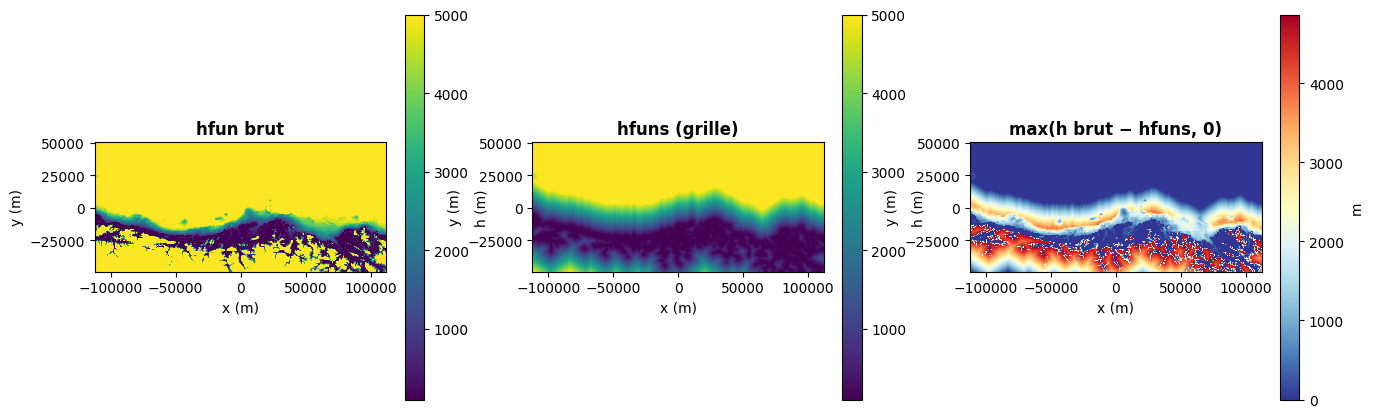

(<Figure size 1600x500 with 6 Axes>,
 array([<Axes: title={'center': 'hfun brut'}, xlabel='x (m)', ylabel='y (m)'>,
        <Axes: title={'center': 'hfuns (grille)'}, xlabel='x (m)', ylabel='y (m)'>,
        <Axes: title={'center': 'max(h brut − hfuns, 0)'}, xlabel='x (m)', ylabel='y (m)'>],
       dtype=object))

In [29]:
plot_hfun(hfuns, hfun)

In [31]:
domain_UTM = reproject_geometry(Poly_dominio, crs, utm_crs)

if domain_UTM.geom_type == "MultiPolygon":
    largest_polygon_domain_UTM = max(domain_UTM.geoms, key=lambda p: p.area)
else:
    largest_polygon_domain_UTM = domain_UTM

In [32]:
from pymesh2d.geom_util.poly_util import resample_polygon_hfun

# Use smoothed sizing function directly
poly_comput_UTM = resample_polygon_hfun(largest_polygon_domain_UTM, hfuns)

if poly_comput_UTM.geom_type == "MultiPolygon":
    poly_comput_UTM = max(poly_comput_UTM.geoms, key=lambda p: p.area)

poly_comput_UTM_clean = clean_polygon(poly_comput_UTM, min_vertices=15)

# Convert to nodes and edges
node_c, edge_c = polygon_to_node_edge(poly_comput_UTM_clean)

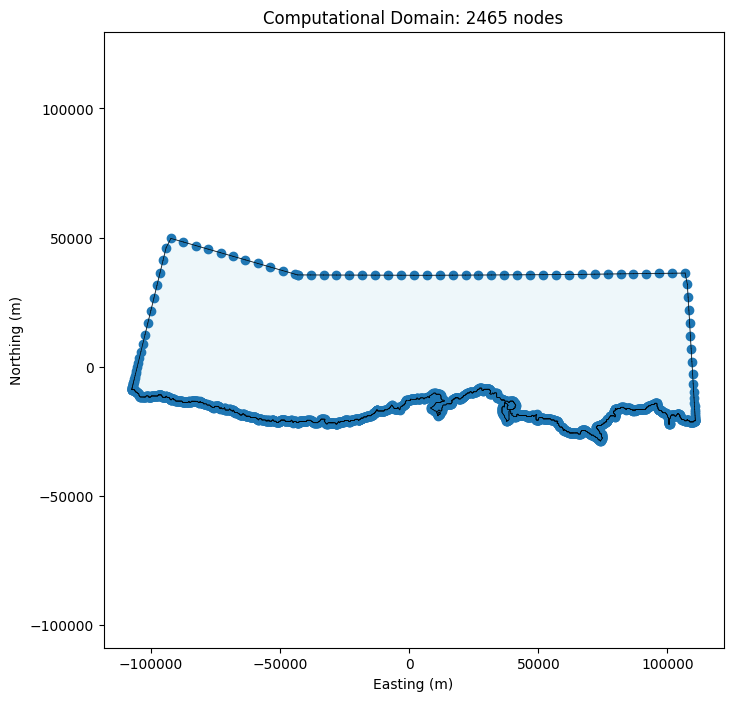

In [33]:
from shapely.plotting import plot_polygon

fig, ax = plt.subplots(figsize=(8, 8))
plot_polygon(poly_comput_UTM_clean, ax=ax, facecolor="lightblue", alpha=0.2)

for e in edge_c.astype(int):
    ax.plot(node_c[e, 0], node_c[e, 1], "k-", lw=0.5)
ax.scatter(node_c[:, 0], node_c[:, 1], color="red", s=2)

ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_title(f"Computational Domain: {len(node_c)} nodes")
ax.axis("equal");

In [34]:
# Mesh generation options
opts_refine = {"kind": "delaunay"}

# Generate and smooth computational mesh
vert_c, etri_c, tria_c, tnum_c = refine(node_c, edge_c, [], opts_refine, hfuns)
# vert_c, etri_c, tria_c, tnum_c = smooth(vert_c, etri_c, tria_c, tnum_c, opts_smooth, hfuns)


 Refine triangulation...

 -------------------------------------------------------
      |ITER.|          |CDT1(X)|          |CDT2(X)|     
 -------------------------------------------------------
          1               2465               2463
         10               2474               6926
         20               2488              23912
         29               2489              25157



In [35]:
opts_smooth = {}

vert_c, etri_c, tria_c, tnum_c = smooth(
    vert_c, etri_c, tria_c, tnum_c, opts_smooth, hfuns
)


 Smooth triangulation...

 -------------------------------------------------------
      |ITER.|          |MOVE(X)|          |DTRI(X)|     
 -------------------------------------------------------
          0              10960              24427
          4               9589              23183
          8               6058              22817
         12               3765              22881
         16               3032              22803
         20               2606              22723
         24               2049              22737
         28               1837              22737



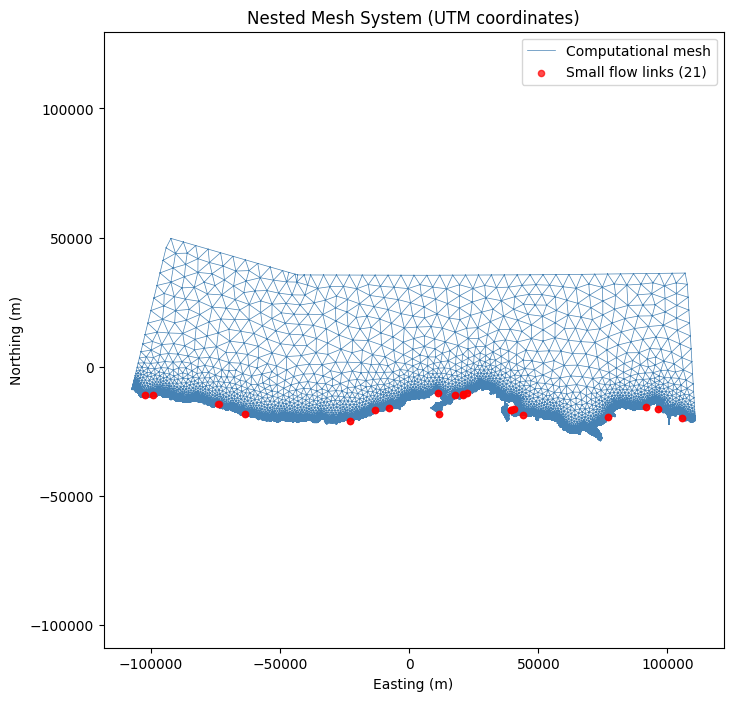

In [36]:
from pymesh2d.mesh_util.circo import small_flow_centers
from pymesh2d.mesh_util.tricon import tricon

# Compute triangle connectivity and identify small flow links
edge_cc, _ = tricon(tria_c, None)

circumcenters, nlinktoosmall = small_flow_centers(
    vert_c, tria_c, edge_cc, removesmalllinkstrsh=0.11, conn=None
)

# Visualize both meshes
fig, ax = plt.subplots(figsize=(8, 8))

ax.triplot(
    vert_c[:, 0],
    vert_c[:, 1],
    tria_c[:, 0:3],
    color="steelblue",
    lw=0.5,
    label="Computational mesh",
)

if nlinktoosmall > 0:
    ax.scatter(
        circumcenters[:, 0],
        circumcenters[:, 1],
        color="red",
        s=20,
        alpha=0.7,
        zorder=5,
        label=f"Small flow links ({nlinktoosmall})",
    )
else:
    ax.text(
        0.02,
        0.98,
        "No small flow links detected",
        transform=ax.transAxes,
        fontsize=12,
        color="green",
        verticalalignment="top",
    )

ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_title("Nested Mesh System (UTM coordinates)")
ax.legend()
ax.axis("equal");

In [38]:
from pymesh2d.geom_util.proj_util import reproject_node
from pymesh2d.smood import smood

vvert_c = reproject_node(vert_c, get_local_utm_crs(crs, lon, lat), crs)

vert_2, etri_2, tria_2, tnum_2 = smood(
    vvert_c,
    etri_c,
    tria_c,
    tnum_c,
    opts={
        "strategy": "continuous",
        "require_both_criteria": True,
        "iter": 24,
        "max_adapt_steps": 12,
        "continuous_stagnation_patience": 2,
        "preserve_merged_quads": True,
    },
)


 Smooth triangulation for Delft3D-FM computation...

 -------------------------------------------------------
      |STATE.|      |MAX|COS(PHI)| |N_SMALL| |N_ZONES|
 -------------------------------------------------------
    initial         0.459042            21          0
    outer=0         0.459042             0          0
    outer=1         0.459042             0          0
    outer=2         0.459042             0          0
    outer=3         0.459042             0          0
    final           0.459042             0          0


In [39]:
from pymesh2d.geomesh_util.interpolation_mesh import interpolate_from_xr

z = interpolate_from_xr(GEBCO_sel, vert_2)

In [40]:
from pymesh2d.geomesh_util.grd_util import adcirc2DFlowFM

ds_out = adcirc2DFlowFM(np.column_stack((vert_2, z)), tria_2)

In [41]:
ds_out.to_netcdf("cantabria_mesh.nc")